#### Sequence models: RNN, Bidirectional RNN, GRU and LSTM

we classify each text into 3 classes (low, medium, high relevance to artificial intelligence). the 4 models have the same structure:

`words (numbers) -> Embedding -> RNN / BiRNN / GRU / LSTM -> last hidden state -> Dropout -> Linear (3 classes)`

only the recurrent layer changes. we tune a few hyper-parameters for each model with the validation set, then we compare the 4 models on the test set

In [1]:
import time
import copy
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

Selected device: cuda


##### data (from the preprocessing notebook)

In [2]:
data = np.load("../dataset/processed.npz")

X_train, y_train = torch.tensor(data["X_train"]), torch.tensor(data["y_train"])
X_val, y_val = torch.tensor(data["X_val"]), torch.tensor(data["y_val"])
X_test, y_test = torch.tensor(data["X_test"]), torch.tensor(data["y_test"])

with open("../dataset/vocab.json", encoding="utf-8") as f:
    vocab_size = len(json.load(f))

print(X_train.shape, X_val.shape, X_test.shape, "| vocabulary:", vocab_size)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=64)

# the classes are not balanced (about 60% / 20% / 20%), so we give more weight to the small classes
counts = np.bincount(y_train.numpy())
class_weights = torch.tensor(len(y_train) / (3 * counts), dtype=torch.float32).to(device)
print("class weights:", class_weights)

criterion = nn.CrossEntropyLoss(weight=class_weights)

torch.Size([3188, 300]) torch.Size([683, 300]) torch.Size([684, 300]) | vocabulary: 19847
class weights: tensor([0.5292, 2.1687, 1.5401], device='cuda:0')


##### the model

the texts are padded with zeros, so we give the real length of each text to the recurrent layer (`pack_padded_sequence`). like this the model does not read the padding

In [3]:
class TextClassifier(nn.Module):
    def __init__(self, rnn_type, bidirectional, vocab_size, embed_dim, hidden_dim, dropout, n_classes=3):
        super().__init__()
        self.rnn_type = rnn_type
        self.bidirectional = bidirectional

        # words -> vectors
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # recurrent layer: nn.RNN, nn.GRU or nn.LSTM
        rnn_class = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[rnn_type]
        self.rnn = rnn_class(embed_dim, hidden_dim, batch_first=True, bidirectional=bidirectional)

        # regularization and output layer
        self.dropout = nn.Dropout(dropout)
        n_directions = 2 if bidirectional else 1
        self.fc = nn.Linear(hidden_dim * n_directions, n_classes)

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()   # real length of each text

        embedded = self.embedding(x)
        packed = pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)

        if self.rnn_type == "LSTM":
            hidden = hidden[0]                   # lstm returns (hidden state, cell state)

        if self.bidirectional:
            out = torch.cat((hidden[-2], hidden[-1]), dim=1)   # forward and backward last states
        else:
            out = hidden[-1]

        return self.fc(self.dropout(out))

# quick check
model = TextClassifier("LSTM", False, vocab_size, 100, 64, 0.3).to(device)
print(model(X_train[:4].to(device)).shape)   # (4, 3)

torch.Size([4, 3])


##### evaluation and training functions

In [4]:
def evaluate(model, loader):
    model.eval()
    all_preds, all_labels, total_loss = [], [], 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            outputs = model(xb)
            total_loss += criterion(outputs, yb).item() * len(yb)
            all_preds.append(outputs.argmax(dim=1).cpu())
            all_labels.append(yb.cpu())
    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    return {
        "loss": total_loss / len(labels),
        "accuracy": 100 * accuracy_score(labels, preds),
        "f1": 100 * f1_score(labels, preds, average="macro"),
        "preds": preds,
        "labels": labels,
    }

In [5]:
def train(model, lr, epochs=30, patience=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state, wait = -1, None, 0

    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # rnn gradients can explode
            optimizer.step()

            running_loss += loss.item() * len(yb)

        val = evaluate(model, val_loader)
        history["train_loss"].append(running_loss / len(y_train))
        history["val_loss"].append(val["loss"])
        history["val_f1"].append(val["f1"])

        # early stopping on the validation F1: we keep the best epoch
        if val["f1"] > best_f1:
            best_f1, best_state, wait = val["f1"], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return history, time.time() - t0, best_f1

##### hyper-parameter tuning

for each of the 4 models we try 8 combinations (hidden size, learning rate, dropout) and we keep the one with the best validation macro F1. the test set is not used here

In [6]:
architectures = {
    "RNN":   ("RNN", False),
    "BiRNN": ("RNN", True),
    "GRU":   ("GRU", False),
    "LSTM":  ("LSTM", False),
}

grid = {
    "hidden_dim": [64, 128],
    "lr": [0.001, 0.003],
    "dropout": [0.3, 0.5],
}
embed_dim = 100

tuning = []
best = {}   # best model of each architecture

for name, (rnn_type, bidirectional) in architectures.items():
    for hidden_dim, lr, dropout in itertools.product(grid["hidden_dim"], grid["lr"], grid["dropout"]):
        torch.manual_seed(0)
        model = TextClassifier(rnn_type, bidirectional, vocab_size, embed_dim, hidden_dim, dropout).to(device)
        history, train_time, val_f1 = train(model, lr)

        tuning.append({"model": name, "hidden_dim": hidden_dim, "lr": lr, "dropout": dropout,
                       "epochs": len(history["val_f1"]), "val_f1": val_f1})
        print(f"{name:6s} hidden={hidden_dim:3d} lr={lr} dropout={dropout} | val F1 = {val_f1:.2f}")

        if name not in best or val_f1 > best[name]["val_f1"]:
            best[name] = {"model": model, "history": history, "train_time": train_time, "val_f1": val_f1,
                          "params": {"hidden_dim": hidden_dim, "lr": lr, "dropout": dropout}}

RNN    hidden= 64 lr=0.001 dropout=0.3 | val F1 = 56.27
RNN    hidden= 64 lr=0.001 dropout=0.5 | val F1 = 55.38
RNN    hidden= 64 lr=0.003 dropout=0.3 | val F1 = 56.86
RNN    hidden= 64 lr=0.003 dropout=0.5 | val F1 = 56.91
RNN    hidden=128 lr=0.001 dropout=0.3 | val F1 = 56.30
RNN    hidden=128 lr=0.001 dropout=0.5 | val F1 = 55.67
RNN    hidden=128 lr=0.003 dropout=0.3 | val F1 = 53.19
RNN    hidden=128 lr=0.003 dropout=0.5 | val F1 = 53.40
BiRNN  hidden= 64 lr=0.001 dropout=0.3 | val F1 = 74.20
BiRNN  hidden= 64 lr=0.001 dropout=0.5 | val F1 = 72.97
BiRNN  hidden= 64 lr=0.003 dropout=0.3 | val F1 = 71.52
BiRNN  hidden= 64 lr=0.003 dropout=0.5 | val F1 = 74.01
BiRNN  hidden=128 lr=0.001 dropout=0.3 | val F1 = 73.66
BiRNN  hidden=128 lr=0.001 dropout=0.5 | val F1 = 74.62
BiRNN  hidden=128 lr=0.003 dropout=0.3 | val F1 = 66.57
BiRNN  hidden=128 lr=0.003 dropout=0.5 | val F1 = 75.13
GRU    hidden= 64 lr=0.001 dropout=0.3 | val F1 = 69.29
GRU    hidden= 64 lr=0.001 dropout=0.5 | val F1 

In [7]:
tuning_df = pd.DataFrame(tuning)
display(tuning_df.sort_values(["model", "val_f1"], ascending=[True, False]).round(2))

for name in best:
    print(name, best[name]["params"], "val F1 =", round(best[name]["val_f1"], 2))

,model,hidden_dim,lr,dropout,epochs,val_f1
15,BiRNN,128,0.0,0.5,17,75.13
13,BiRNN,128,0.0,0.5,12,74.62
8,BiRNN,64,0.0,0.3,19,74.20
11,BiRNN,64,0.0,0.5,12,74.01
12,BiRNN,128,0.0,0.3,8,73.66
9,BiRNN,64,0.0,0.5,19,72.97
10,BiRNN,64,0.0,0.3,8,71.52
14,BiRNN,128,0.0,0.3,13,66.57
22,GRU,128,0.0,0.3,14,81.37
23,GRU,128,0.0,0.5,9,80.99


RNN {'hidden_dim': 64, 'lr': 0.003, 'dropout': 0.5} val F1 = 56.91
BiRNN {'hidden_dim': 128, 'lr': 0.003, 'dropout': 0.5} val F1 = 75.13
GRU {'hidden_dim': 128, 'lr': 0.003, 'dropout': 0.3} val F1 = 81.37
LSTM {'hidden_dim': 64, 'lr': 0.001, 'dropout': 0.5} val F1 = 66.12


##### evaluation on the test set

In [8]:
results = {}
for name in best:
    res = evaluate(best[name]["model"], test_loader)
    results[name] = {
        "Accuracy (%)": res["accuracy"],
        "F1 macro (%)": res["f1"],
        "Loss": res["loss"],
        "Training time (s)": best[name]["train_time"],
        "Epochs": len(best[name]["history"]["val_f1"]),
        "Params (M)": sum(p.numel() for p in best[name]["model"].parameters()) / 1e6,
    }
    best[name]["test"] = res

table = pd.DataFrame(results).T.round(3)
display(table)

,Accuracy (%),F1 macro (%),Loss,Training time (s),Epochs,Params (M)
RNN,74.269,56.066,0.894,10.370,7.0,1.996
BiRNN,83.187,73.805,1.604,38.058,17.0,2.044
GRU,85.965,77.527,1.254,20.786,14.0,2.073
LSTM,76.608,62.795,1.277,24.394,16.0,2.027


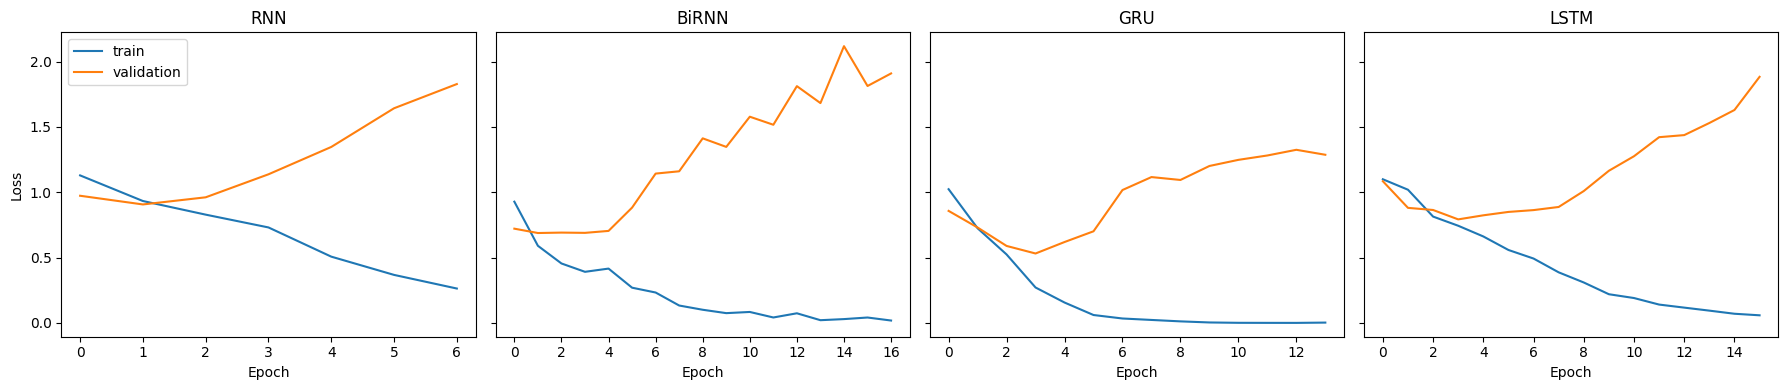

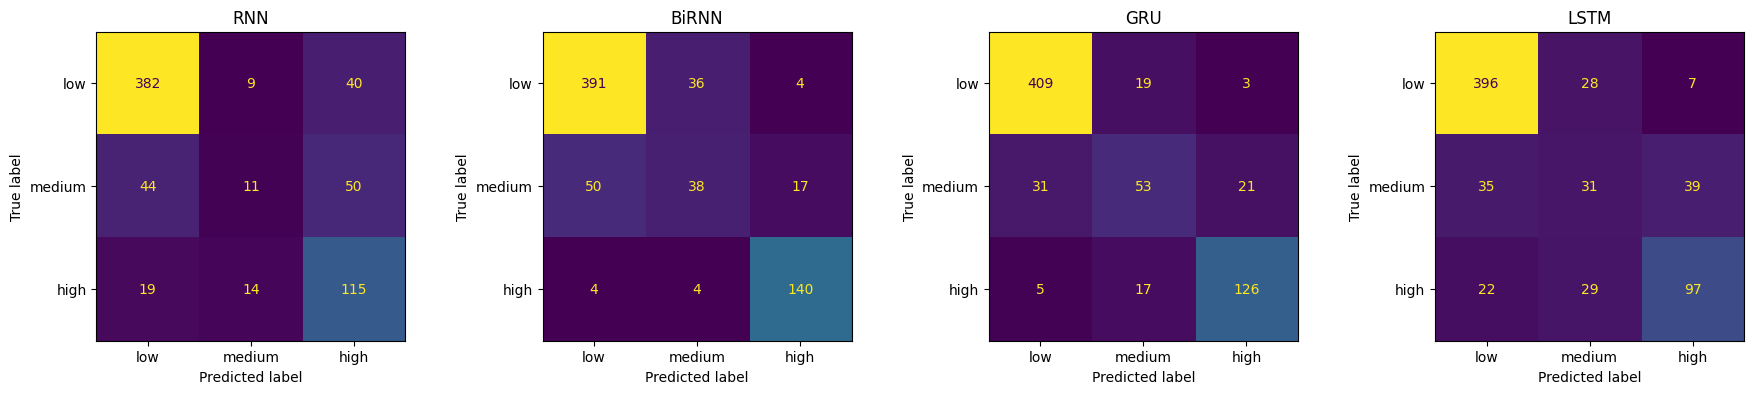

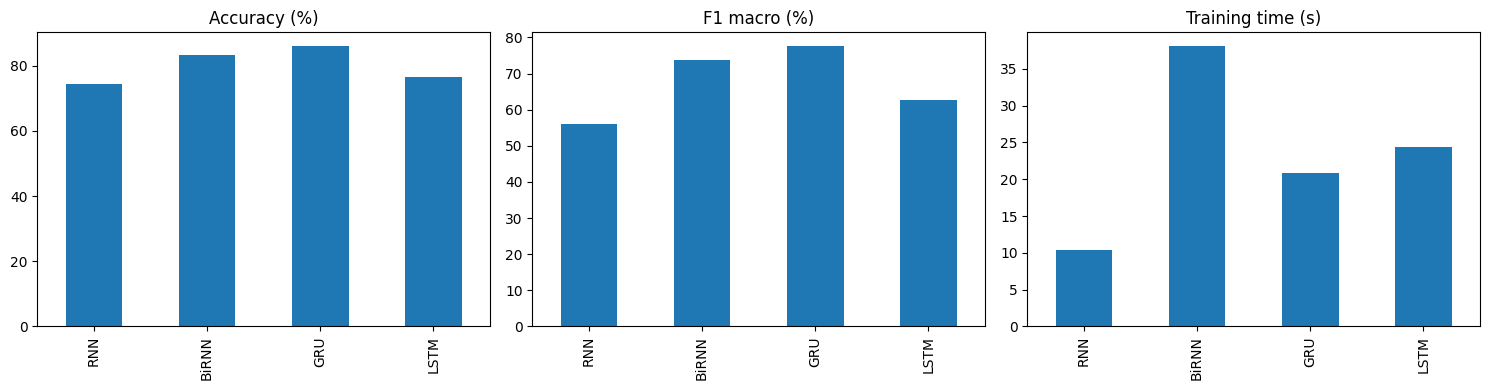

In [9]:
import os
os.makedirs("../figures", exist_ok=True)

# training curves of the best models
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, name in zip(axes, best):
    ax.plot(best[name]["history"]["train_loss"], label="train")
    ax.plot(best[name]["history"]["val_loss"], label="validation")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
plt.tight_layout()
plt.savefig("../figures/models_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

# confusion matrices on the test set
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, best):
    cm = confusion_matrix(best[name]["test"]["labels"], best[name]["test"]["preds"])
    ConfusionMatrixDisplay(cm, display_labels=["low", "medium", "high"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("../figures/models_confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

# comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
table["Accuracy (%)"].plot.bar(ax=axes[0], title="Accuracy (%)")
table["F1 macro (%)"].plot.bar(ax=axes[1], title="F1 macro (%)")
table["Training time (s)"].plot.bar(ax=axes[2], title="Training time (s)")
plt.tight_layout()
plt.savefig("../figures/models_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

##### BLEU score

BLEU compares a generated text with a reference text, so it is made for translation and text generation, not for classification. here the output of a model is only one class per text. as the lab asks for it, we compute a BLEU score between the sequence of predicted classes and the sequence of true classes of the test set (bigrams).

this number is **not a good metric here**: BLEU counts how many words (classes) appear in both sequences, and it does not check that each prediction is on the right text. so a model can have a high BLEU with a low accuracy. we keep it only because the lab asks for it, and we use accuracy and macro F1 to compare the models. we will use BLEU on real text in part 2 (GPT-2)

In [10]:
# pip install nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

bleu = {}
for name in best:
    reference = [str(c) for c in best[name]["test"]["labels"]]
    prediction = [str(c) for c in best[name]["test"]["preds"]]
    bleu[name] = sentence_bleu([reference], prediction, weights=(0.5, 0.5), smoothing_function=SmoothingFunction().method1)

table["BLEU"] = pd.Series(bleu)
display(table.round(3))

,Accuracy (%),F1 macro (%),Loss,Training time (s),Epochs,Params (M),BLEU
RNN,74.269,56.066,0.894,10.370,7.0,1.996,0.856
BiRNN,83.187,73.805,1.604,38.058,17.0,2.044,0.948
GRU,85.965,77.527,1.254,20.786,14.0,2.073,0.968
LSTM,76.608,62.795,1.277,24.394,16.0,2.027,0.958


#### Conclusion:

The **GRU** is the best model on the test set (86.0% accuracy, 77.5% macro F1), followed by the **bidirectional RNN** (83.2% and 73.8%). The **LSTM** is third (76.6% and 62.8%) and the plain **RNN** is the worst (74.3% and 56.1%). The ranking is the same on the validation set, so it is not an accident of the test set.

Why this order? The texts are long (300 words after cutting), and the plain RNN forgets the beginning of the text when it reaches the end (vanishing gradient), so it learns very little. The GRU and the LSTM have gates that keep the important information, and the bidirectional RNN reads the text in both directions, which also helps. The GRU being better than the LSTM is not a general rule: a GRU cell is simpler (3 gates against 4), and our dataset is small (3188 training texts), so it is easier to train. With another dataset the LSTM could win.

The "medium" class is the hardest for all the models (the GRU finds only 53 of 105 medium texts, the plain RNN only 11): it is the smallest class and it sits between the two others, so even a human would hesitate. The training curves show strong overfitting: the validation loss is the lowest around epoch 3 or 4, then it grows while the training loss goes to 0. We stop on the validation F1 and not on the loss, so the kept epoch is later than the best loss, and this is why the test loss is high (0.9 to 1.6) even if the F1 is good.

Two limits to keep in mind. First, the labels come from keyword counts, so the models can partly learn to count keywords, and the website is also linked to the class (aitnews is mostly "high"). Second, BLEU is not a good metric for a classification task, it does not follow the F1 (the LSTM has a higher BLEU than the bidirectional RNN with a lower F1), so we compare the models with accuracy and macro F1.

Compared with our first try on 894 texts (macro F1 between 45 and 60 for the four models, with only one hyper-parameter combination each), the new dataset of 4555 texts gives between 56 and 78: the quantity of data was the biggest improvement.